# Missing company information: is it random?

company_size and company_type are the two columns with the most missing values (about 31 % and 32 %). Before we fill these gaps we need to know **why** they are missing, because that decides which method is safe.

This notebook checks one question: **does the missing company information depend on relevant_experience?**

It uses the converted data from `fix_data.ipynb` (`customer_train_typed.pkl`), so run that notebook first.

## Why the reason for missing values matters

There are three types of missing values:

| Type | Meaning | What it means for us |
|---|---|---|
| MCAR (missing completely at random) | missingness has nothing to do with the data | dropping or simple filling adds no bias |
| MAR (missing at random) | missingness depends on other columns we can see | fill the gaps using these other columns |
| MNAR (missing not at random) | missingness depends on the missing value itself | every simple fix biases the result, the missingness itself is information |

If people without relevant experience leave the company fields empty much more often, the values are **not** missing completely at random. Then filling them with the most common value (mode imputation) would distort the data.

Careful: a test can show that data are not MCAR, but it can never prove MCAR. MAR vs. MNAR needs domain knowledge.

## 1. Loading the data

We load the pickle file, so all data types from `fix_data.ipynb` are already there. `relevant_experience` is a bool column (True = has relevant experience).

We work on a copy, so the loaded data stays as it is.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

ds_jobs = pd.read_pickle("customer_train_typed.pkl")

# Create a copy
ds_jobs_transformed = ds_jobs.copy()

## 2. Method

For each of the two columns the code does four things:

1. **Missingness indicator:** a new column that is 1 if the value is missing and 0 if not. This turns "is it missing?" into something we can count.
2. **Crosstab:** a table that counts how often each combination occurs, e.g. "no relevant experience and company_size missing".
3. **Chi-square test:** checks if the two variables are independent.
   - Null hypothesis: missingness and relevant_experience have nothing to do with each other.
   - The p-value is the probability of seeing a difference this large if the null hypothesis were true.
   - If p is below 0.05, we reject the null hypothesis: missingness depends on relevant_experience.
4. **Bar chart:** the share of missing values for students with and without relevant experience. The test tells us **whether** there is a difference, the chart shows **how big** it is.

A small example of the crosstab for company_size, before the full analysis:

In [5]:
pd.crosstab(
    ds_jobs_transformed["relevant_experience"],
    ds_jobs_transformed["company_size"].isna(),
    rownames=["relevant experience"],
    colnames=["company_size missing"],
)

company_size missing,False,True
relevant experience,,
False,2009,3357
True,11211,2581


## 3. Analysis

The loop runs the four steps for company_size and company_type and draws one chart per column. The p-value is shown in the chart title and printed below.

`zip(axes, columns)` pairs each chart area with one column, so the first column is drawn on the left and the second on the right.

company_size: Chi² = 3470.37, p = 0.000e+00
company_type: Chi² = 2474.19, p = 0.000e+00


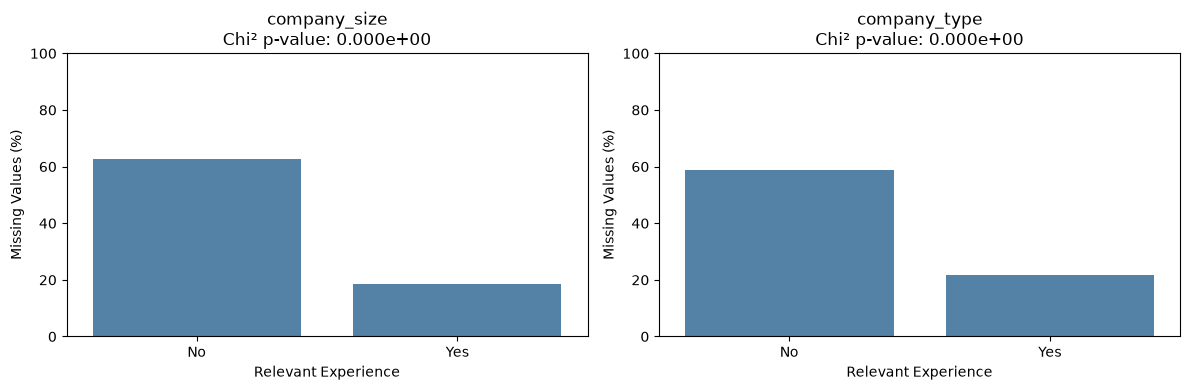

In [6]:
# Variables to analyze
columns = ["company_size", "company_type"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, columns):

    # Missingness indicator
    ds_jobs_transformed[f"{col}_missing"] = (
        ds_jobs_transformed[col].isna().astype(int)
    )

    # Chi-square test
    table = pd.crosstab(
        ds_jobs_transformed["relevant_experience"],
        ds_jobs_transformed[f"{col}_missing"]
    )

    chi2, p, _, _ = chi2_contingency(table)

    # Missing percentage by experience
    missing_pct = (
        ds_jobs_transformed.groupby("relevant_experience")
        [f"{col}_missing"].mean() * 100
    )
    # relevant_experience is bool, so show readable labels instead of False / True
    missing_pct.index = missing_pct.index.map({False: "No", True: "Yes"})

    sns.barplot(
        x=missing_pct.index,
        y=missing_pct.values,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"{col}\nChi² p-value: {p:.3e}")
    ax.set_xlabel("Relevant Experience")
    ax.set_ylabel("Missing Values (%)")
    ax.set_ylim(0, 100)

    print(f"{col}: Chi² = {chi2:.2f}, p = {p:.3e}")

plt.tight_layout()
plt.show()

## 4. Reading the result

- **p-value:** far below 0.05 means the missingness clearly depends on relevant_experience.
- **Bars:** the higher bar shows the group where company information is missing more often.
- With 19,158 rows even small differences become significant, so always look at the size of the difference in the chart as well, not only at p.

## 5. Conclusion

The missing values in company_size and company_type are **not missing completely at random**, they are connected to relevant_experience. A plausible reason: many people without relevant experience don't have a current employer, so there is no company to describe.

That's why we don't use mode imputation here. Filling every gap with the most common value ("Pvt Ltd", "50-99") would give students without a job a company they don't have.

Better options for the next step:

- a separate category like "Unknown" or "No company", so the information "missing" is kept
- keeping the `_missing` indicator as an extra feature for the model

## 6. Who is behind the missing values?

Section 3 asked: **how often** is company information missing in each group?

Now we turn the question around: **if company_size or company_type is missing, what does relevant_experience say?** Do all of these students have no relevant experience, or only some of them?

Steps per column:

1. Keep only the rows where the value is missing (`.isna()` as a filter).
2. Count relevant_experience in these rows (`.value_counts()`).
3. Draw the counts as bars, with the number and the share on top of each bar.

company_size missing: No = 3,357 (56.5 %), Yes = 2,581 (43.5 %)
company_type missing: No = 3,163 (51.5 %), Yes = 2,977 (48.5 %)


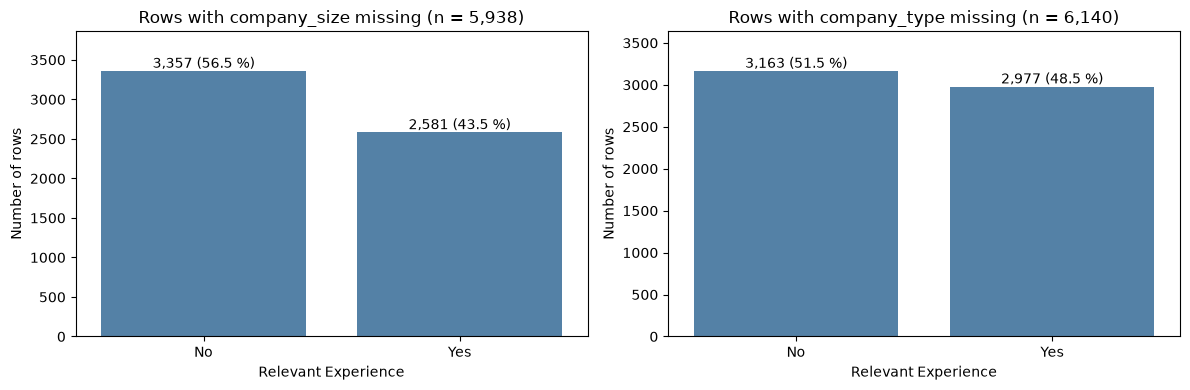

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, columns):

    # Only the rows where the value is missing
    missing_rows = ds_jobs_transformed[ds_jobs_transformed[col].isna()]

    # Count relevant_experience in these rows
    counts = missing_rows["relevant_experience"].value_counts().sort_index()
    counts.index = counts.index.map({False: "No", True: "Yes"})
    shares = counts / counts.sum() * 100

    sns.barplot(
        x=counts.index,
        y=counts.values,
        ax=ax,
        color="steelblue"
    )

    # Number and share on top of each bar
    for i, (n, pct) in enumerate(zip(counts.values, shares.values)):
        ax.text(i, n, f"{n:,} ({pct:.1f} %)", ha="center", va="bottom")

    ax.set_title(f"Rows with {col} missing (n = {counts.sum():,})")
    ax.set_xlabel("Relevant Experience")
    ax.set_ylabel("Number of rows")
    ax.set_ylim(0, counts.max() * 1.15)

    print(f"{col} missing: No = {counts['No']:,} ({shares['No']:.1f} %), "
          f"Yes = {counts['Yes']:,} ({shares['Yes']:.1f} %)")

plt.tight_layout()
plt.show()

## 7. Reading the result

| Missing | No relevant experience | Relevant experience | Total |
|---|---|---|---|
| company_size | 3,357 (56.5 %) | 2,581 (43.5 %) | 5,938 |
| company_type | 3,163 (51.5 %) | 2,977 (48.5 %) | 6,140 |

- **Not all** missing company values belong to students without relevant experience. Both groups are almost equally large.
- That fits section 3: without relevant experience the values are missing about three times as often, but this group is much smaller (5,366 vs. 13,792). So in absolute numbers both groups end up close together.
- "No current employer" explains only part of the missing values. For about 2,600 to 3,000 students with relevant experience the company information is missing as well, maybe because they didn't fill it in.

Consequence: we can't fill the gaps with a fixed rule like "no relevant experience means no company". A separate category "Unknown" plus the `_missing` indicator stays the safer choice.

## 8. How to handle the missing values

Section 6 shows that there is not **one** reason behind the gaps, but at least two:

- **No employer:** there is no company to describe. The field is really "empty", not "unknown".
- **Not filled in:** there is a company, but the student skipped the field.

The data can't tell these two cases apart.

| Method | Idea | Fits here? |
|---|---|---|
| Drop rows | throw away every row with a gap | ❌ we lose about 30 % of the data, mostly students without experience, so the sample gets skewed |
| Mode imputation | fill in "Pvt Ltd" / "50-99" everywhere | ❌ students without a job get a company they don't have (section 5) |
| Fixed rule | "no experience means no company" | ❌ section 6: almost half of the gaps come from students with experience |
| Own category "Unknown" | the gap becomes a value of its own | ✅ simple, honest, keeps the information "something is missing here" |
| Keep the `_missing` indicator | 0/1 column as an extra feature | ✅ a model can learn by itself if "missing" predicts job_change |
| Predict from other columns | e.g. KNN or a model estimates the value | ⚠️ a lot of effort, and for students without an employer there is no real value to estimate |

Decision: **"Unknown" category + `_missing` indicator.**

Also supports the "no employer" reason: company_size and company_type are mostly missing together, only 1,358 rows (7.1 %) have just one of them missing (see `fix_data.ipynb`, step 3).

### Things to watch out for when filling the gaps

1. **Data type:** both columns are of type `category`. `fillna("Unknown")` fails because "Unknown" is not an allowed category yet, so it has to be added first (`.cat.add_categories()`).
2. **Ordered category:** company_size is ordered (`<10` < `10-49` < ...). "Unknown" has no sensible place in this order, so decide if the column stays ordered after filling.
3. **Check afterwards:** `.isna().sum()` should be 0 for both columns.